# UTS Klasifikasi dengan Decision Tree & K-Nearest Neighbors (KNN): Heart Disease

## 1. Import Library & Pengaturan

In [2]:
# 202431048_Kania Pratiwi

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_DIR = ""

## 2. Load & Cek Data

In [3]:
# 202431048_Kania Pratiwi

df = pd.read_csv(DATA_DIR + "01_heart_disease.csv")
print("Ukuran data :", df.shape)
display(df.head())
print("\nMissing value :", df.isnull().sum().sum())
print("Data duplikat :", df.duplicated().sum())
print("\nDistribusi target:")
print(df["HeartDisease"].value_counts())

Ukuran data : (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



Missing value : 0
Data duplikat : 0

Distribusi target:
HeartDisease
1    508
0    410
Name: count, dtype: int64


In [4]:
# 202431048_Kania Pratiwi

print("Cholesterol = 0 :", (df["Cholesterol"] == 0).sum(), "baris")
print("RestingBP   = 0 :", (df["RestingBP"] == 0).sum(), "baris")

Cholesterol = 0 : 172 baris
RestingBP   = 0 : 1 baris


## 3.Preprocessing & Split Data

In [5]:
# 202431048_Kania Pratiwi

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

def buat_preprocessor(X, scaling):
    kol_num = X.select_dtypes(include="number").columns.tolist()
    kol_kat = [c for c in X.columns if c not in kol_num]
    num_tf = StandardScaler() if scaling else "passthrough"
    return ColumnTransformer([
        ("num", num_tf, kol_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), kol_kat),
    ])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Data train:", X_train.shape, "| Data test:", X_test.shape)

Data train: (734, 11) | Data test: (184, 11)


## 4. Decision Tree (GridSearchCV)

In [6]:
# 202431048_Kania Pratiwi

pipe_dt = Pipeline([
    ("prep", buat_preprocessor(X, scaling=False)),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
grid_dt = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 5, 7, 10, None],
    "clf__min_samples_leaf": [1, 5, 10],
}
gs_dt = GridSearchCV(pipe_dt, grid_dt, cv=5, scoring="f1_macro", n_jobs=-1)
gs_dt.fit(X_train, y_train)

print("Parameter terbaik :", gs_dt.best_params_)
print("Skor CV (F1-macro):", round(gs_dt.best_score_, 4))

Parameter terbaik : {'clf__criterion': 'gini', 'clf__max_depth': 3, 'clf__min_samples_leaf': 10}
Skor CV (F1-macro): 0.8404


## 5. KNN (GridSearchCV)

In [7]:
# 202431048_Kania Pratiwi

pipe_knn = Pipeline([
    ("prep", buat_preprocessor(X, scaling=True)),
    ("clf", KNeighborsClassifier()),
])
grid_knn = {
    "clf__n_neighbors": [3, 5, 7, 11, 15],
    "clf__weights": ["uniform", "distance"],
}
gs_knn = GridSearchCV(pipe_knn, grid_knn, cv=3, scoring="f1_macro", n_jobs=-1)
gs_knn.fit(X_train, y_train)

print("Parameter terbaik :", gs_knn.best_params_)
print("Skor CV (F1-macro):", round(gs_knn.best_score_, 4))

Parameter terbaik : {'clf__n_neighbors': 11, 'clf__weights': 'uniform'}
Skor CV (F1-macro): 0.8659


## 6. Evaluasi pada Data Test

In [8]:
# 202431048_Kania Pratiwi

kelas = ["0 (normal)", "1 (penyakit jantung)"]
model = {"Decision Tree": gs_dt.best_estimator_, "KNN": gs_knn.best_estimator_}
pred, hasil = {}, []

for nama, m in model.items():
    p = m.predict(X_test); pred[nama] = p
    print(f"=== {nama} ===")
    print(classification_report(y_test, p, target_names=kelas, digits=3))
    hasil.append({"Model": nama,
                  "Accuracy": accuracy_score(y_test, p),
                  "Precision": precision_score(y_test, p, average="macro"),
                  "Recall": recall_score(y_test, p, average="macro"),
                  "F1-macro": f1_score(y_test, p, average="macro")})

df_hasil = pd.DataFrame(hasil)
display(df_hasil.round(4))

=== Decision Tree ===
                      precision    recall  f1-score   support

          0 (normal)      0.769     0.854     0.809        82
1 (penyakit jantung)      0.871     0.794     0.831       102

            accuracy                          0.821       184
           macro avg      0.820     0.824     0.820       184
        weighted avg      0.826     0.821     0.821       184

=== KNN ===
                      precision    recall  f1-score   support

          0 (normal)      0.914     0.902     0.908        82
1 (penyakit jantung)      0.922     0.931     0.927       102

            accuracy                          0.918       184
           macro avg      0.918     0.917     0.917       184
        weighted avg      0.918     0.918     0.918       184



,Model,Accuracy,Precision,Recall,F1-macro
0,Decision Tree,0.8207,0.8201,0.8239,0.8200
1,KNN,0.9185,0.9180,0.9169,0.9174


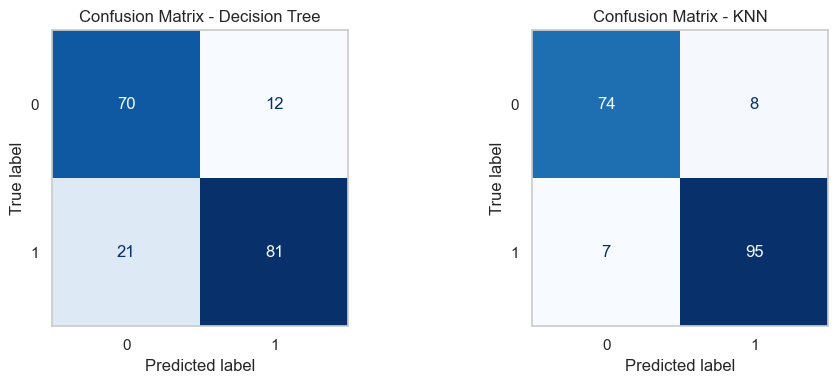

In [9]:
# 202431048_Kania Pratiwi

# Confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, nama in zip(ax, pred):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred[nama]),
                           display_labels=["0", "1"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion Matrix - {nama}")
    a.grid(False)
plt.tight_layout()
plt.show()

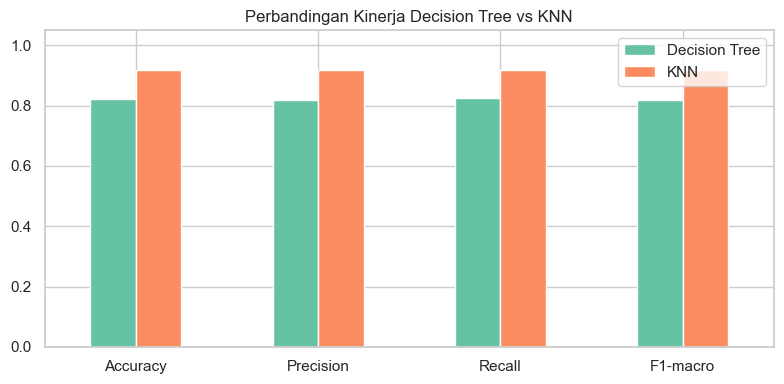

In [10]:
# 202431048_Kania Pratiwi

# Grafik perbandingan metrik
df_hasil.set_index("Model").T.plot(kind="bar", figsize=(8, 4), color=["#66c2a5", "#fc8d62"])
plt.title("Perbandingan Kinerja Decision Tree vs KNN")
plt.ylim(0, 1.05); plt.xticks(rotation=0); plt.legend(title="")
plt.tight_layout(); plt.show()

## 7. Feature Importance & Visualisasi Pohon

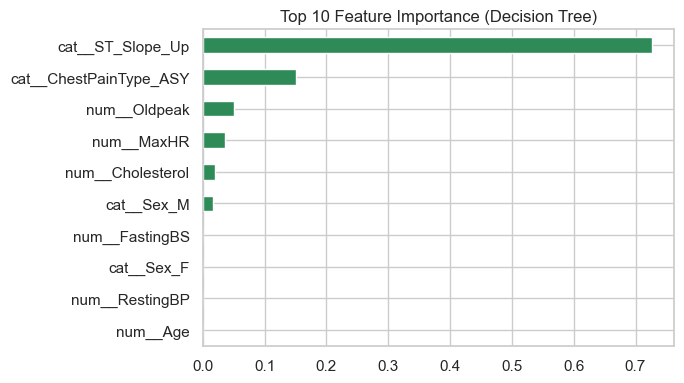

In [11]:
# 202431048_Kania Pratiwi

best_dt = gs_dt.best_estimator_
nama_fitur = best_dt.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_dt.named_steps["clf"].feature_importances_, index=nama_fitur)

plt.figure(figsize=(7, 4))
imp.nlargest(10).sort_values().plot.barh(color="seagreen")
plt.title("Top 10 Feature Importance (Decision Tree)")
plt.tight_layout(); plt.show()

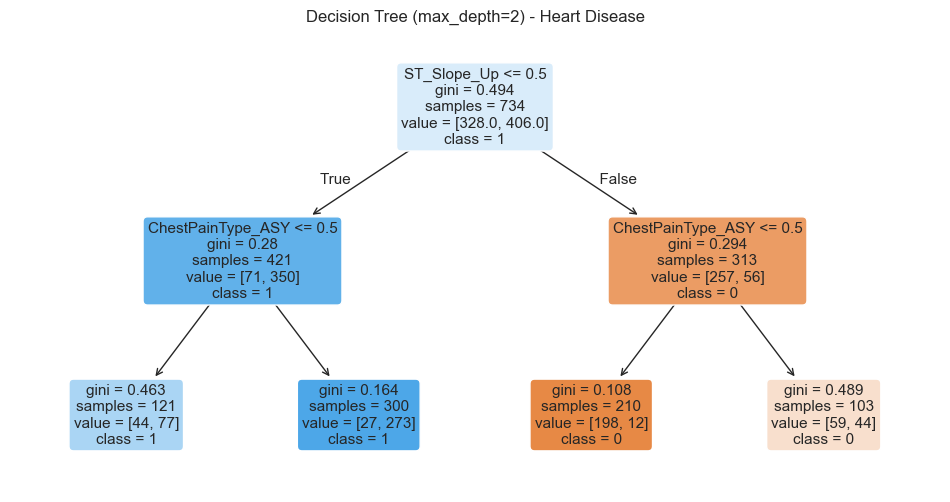

In [12]:
# 202431048_Kania Pratiwi

# Pohon dibatasi max_depth=2 agar mudah dibaca (ubah ke 3 jika ingin lebih detail)
dt_vis = Pipeline([
    ("prep", buat_preprocessor(X, scaling=False)),
    ("clf", DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

plt.figure(figsize=(12, 6))
plot_tree(dt_vis.named_steps["clf"],
          feature_names=[f.split("__", 1)[1] for f in dt_vis.named_steps["prep"].get_feature_names_out()],
          class_names=["0", "1"], filled=True, rounded=True, fontsize=11)
plt.title("Decision Tree (max_depth=2) - Heart Disease")
plt.show()